<a href="https://colab.research.google.com/github/Atherizz/ML_2026/blob/main/JS11/praktikum5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/Atherizz/ML_2026/blob/main/JS11/praktikum5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
# Mount Google Drive (Opsional jika dijalankan di Google Colab)
try:
    from google.colab import drive
    drive.mount('/content/drive')
except Exception:
    pass

Mounted at /content/drive


In [7]:
# Import Required Libraries
from pathlib import Path
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import cv2
import random
import numpy as np
import pandas as pd
import os

# Konfigurasi lokasi direktori gambar
# Mendeteksi otomatis apakah dijalankan di Google Drive Colab, folder Download lokal, atau folder project
possible_paths = [
    Path('/content/drive/MyDrive/ML/images'),
    Path('images')
]

base_dir = None
for p in possible_paths:
    if (p / 'training').exists():
        base_dir = p
        break
    elif (p / 'images' / 'training').exists():
        base_dir = p / 'images'
        break

if base_dir is None:
    # Default path jika belum ditemukan
    base_dir = Path(r'C:\Users\ASUS\Downloads\images\images')

train_dir = base_dir / 'training'
test_dir = base_dir / 'test'

print(f"Base Directory : {base_dir}")
print(f"Train Directory: {train_dir} (Exists: {train_dir.exists()})")
print(f"Test Directory : {test_dir} (Exists: {test_dir.exists()})")

Base Directory : /content/drive/MyDrive/ML/images/images
Train Directory: /content/drive/MyDrive/ML/images/images/training (Exists: True)
Test Directory : /content/drive/MyDrive/ML/images/images/test (Exists: True)


In [8]:
def load_dataset(img_dir):
    p = Path(img_dir)
    # Ambil subdirektori (day dan night)
    dirs = [d for d in p.glob('*') if d.is_dir() and not d.name.startswith('.') and d.name != '__MACOSX']

    img_list = []

    for d in dirs:
        label = d.name  # Nama folder: 'day' atau 'night'
        for file in d.glob('*.jpg'):
            # Abaikan file metadata Mac jika ada
            if file.name.startswith('._'):
                continue
            img = mpimg.imread(str(file))

            if img is not None:
                img_list.append((img, label))

    return img_list

In [9]:
# Load training data
train_img = load_dataset(train_dir)
print(f"Total gambar training berhasil dimuat: {len(train_img)}")

Total gambar training berhasil dimuat: 240


In [10]:
# Check the first data
# It should be a tuple consist of arrays of image and image labels
print("Label data pertama:", train_img[0][1])
print("Dimensi array gambar pertama:", train_img[0][0].shape)

Label data pertama: night
Dimensi array gambar pertama: (700, 1280, 3)


In [11]:
# Random size checking
pick_random = np.random.randint(0, len(train_img))

# Check img size
print(f'Image {pick_random}')
print(train_img[pick_random][0].shape)

Image 177
(471, 640, 3)


Shape	: (372, 640, 3)
Label	: night (night)


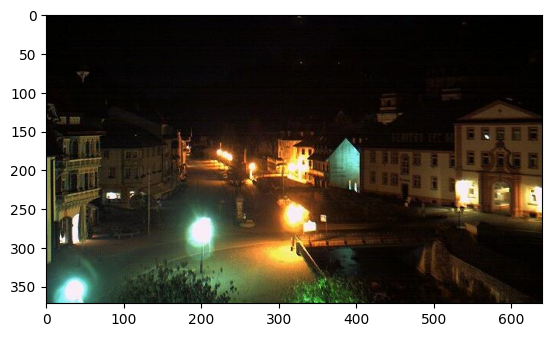

In [12]:
# Function to Visualize
def random_img_viz(img_list):
    rand_num = np.random.randint(0, len(img_list))

    img = img_list[rand_num][0]
    label = img_list[rand_num][1]
    label_str = 'day' if label in [1, 'day'] else 'night'

    plt.imshow(img)
    print(f'Shape\t: {img.shape}')
    print(f'Label\t: {label} ({label_str})')

random_img_viz(train_img)

In [13]:
def standarized_input(image):
    # resize to w: 1100, h:600
    std_img = cv2.resize(image, (1100, 600))
    return std_img

In [14]:
def label_encoder(label):
    # Encode the label
    # day as 1; night as 0
    num_val = 0
    if label == 'day' or label == 1:
        num_val = 1
    return num_val

In [15]:
def preprocess(img_list):
    std_img_list = []

    for item in img_list:
        image = item[0]
        label = item[1]

        # Standarized the image
        std_img = standarized_input(image)

        # Create the label
        img_label = label_encoder(label)

        std_img_list.append((std_img, img_label))

    return std_img_list

In [16]:
train_std_img_list = preprocess(train_img)

In [17]:
# Random size checking
pick_random = np.random.randint(0, len(train_std_img_list))

# Check img size
print(f'Image {pick_random}')
print(train_std_img_list[pick_random][0].shape)

Image 48
(600, 1100, 3)


Shape	: (600, 1100, 3)
Label	: 1 (day)


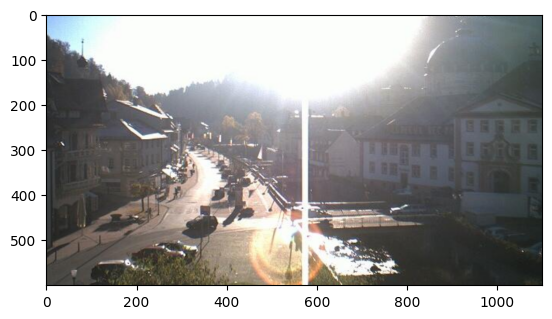

In [18]:
random_img_viz(train_std_img_list)

In [19]:
# Get feature based on average brightness using HSV colorspace
def avg_brightness(image):
    # Convert image to HSV
    img_hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)

    # Calculate the avg of brightness
    sum_brightness = np.sum(img_hsv[:,:,2]) # take the 3rd value which is the V channel
    area = image.shape[0] * image.shape[1]
    avg = sum_brightness / area

    return avg

Image 224
Avg Brightness: 107.3585


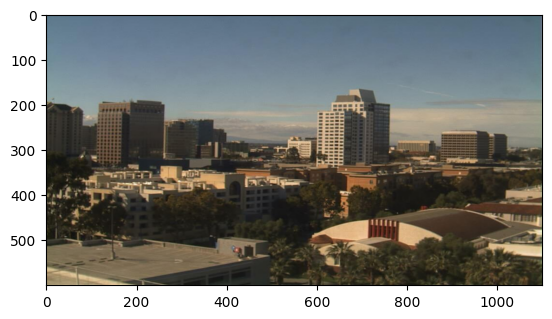

In [20]:
# Check on random image
rand_img = np.random.randint(0, len(train_std_img_list))

feature_img = train_std_img_list[rand_img][0]

avg_img = avg_brightness(feature_img)

print(f'Image {rand_img}')
print(f'Avg Brightness: {avg_img:.4f}')
plt.imshow(feature_img)

In [21]:
def predict_label(img, threshold):
    # Compute average brightness
    avg = avg_brightness(img)
    pred = 0

    # Predict the label based on user defined threshold
    if avg > threshold:
        pred = 1

    return pred

Image 28
Actual label: 0
Predicted label: 0


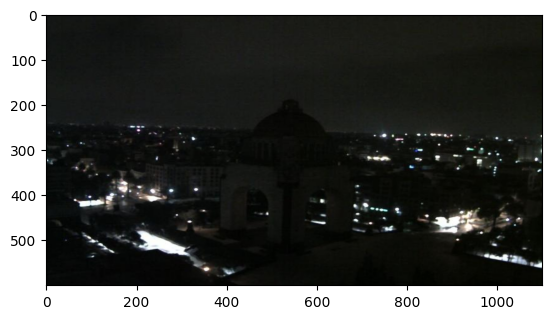

In [22]:
# Test the classifier on train data
rand_img = np.random.randint(0, len(train_std_img_list))

pred = predict_label(train_std_img_list[rand_img][0], threshold=120)

# Evaluate
print(f'Image {rand_img}')
print(f'Actual label: {train_std_img_list[rand_img][1]}')
print(f'Predicted label: {pred}')
plt.imshow(train_std_img_list[rand_img][0])

In [23]:
def evaluate(img_list, threshold):
    miss_labels = []

    for file in img_list:
        # Get the ground truth / correct label
        img = file[0]
        label = file[1]

        # Get prediction
        pred_label = predict_label(img, threshold)

        # Compare ground truth and pred
        if pred_label != label:
            miss_labels.append((img, pred_label, label))

    total_img = len(img_list)
    corr_pred = total_img - len(miss_labels)
    accuracy = corr_pred / total_img

    print(f'Accuracy: {accuracy:.4f}')

In [24]:
# Evaluate on train data
evaluate(train_std_img_list, threshold=120)

Accuracy: 0.8417


In [25]:
# Evaluate on test data

# Load test data
test_img = load_dataset(test_dir)

# Preprocess
test_std_img_list = preprocess(test_img)

# Predict
evaluate(test_std_img_list, threshold=120)

Accuracy: 0.8688


In [26]:
# Create function to extract feature for every images and stored in tabular data
# Stored in Pandas dataframe
def extract_avg_bright_feature(img_list):
    avg_list = []
    labels = []

    for img in img_list:
        img_avg = avg_brightness(img[0]) # Get the avg brightness from image
        img_label = img[1] # Get the image label

        avg_list.append(img_avg)
        labels.append(img_label)

    # Stack data in columnar way
    data = np.column_stack((avg_list, labels))
    # Create a Pandas dataframe
    df = pd.DataFrame(data, columns=['AVG_BRIGHT', 'LABELS'])

    return df

In [27]:
# Extract feature on train data
train_avg_img = extract_avg_bright_feature(train_std_img_list)
print(f'Shape: {train_avg_img.shape}')
train_avg_img.head()

Shape: (240, 2)


,AVG_BRIGHT,LABELS
0,99.623588,0.0
1,35.963767,0.0
2,101.579750,0.0
3,38.835795,0.0
4,85.889741,0.0


In [28]:
# Do the same thing on test data
test_avg_img = extract_avg_bright_feature(test_std_img_list)
print(f'Shape: {test_avg_img.shape}')
test_avg_img.head()

Shape: (160, 2)


,AVG_BRIGHT,LABELS
0,157.918309,1.0
1,183.717738,1.0
2,132.523694,1.0
3,127.443791,1.0
4,150.264005,1.0


In [29]:
# import required library
from sklearn.svm import SVC

# Split data and label
X_train = train_avg_img.iloc[:,0].values.reshape(-1,1)
y_train = train_avg_img.iloc[:,1]
X_test = test_avg_img.iloc[:,0].values.reshape(-1,1)
y_test = test_avg_img.iloc[:,1]

model = SVC()
model.fit(X_train, y_train)

SVC()

In [30]:
from sklearn.metrics import accuracy_score

# Make a prediction on train data
y_train_pred = model.predict(X_train)

# Get the accuracy on train data
acc_train = accuracy_score(y_train, y_train_pred)

# Make a prediction on test data
y_test_pred = model.predict(X_test)

# Get the accuracy on test data
acc_test = accuracy_score(y_test, y_test_pred)

# Print Eval Result
print(f'Accuracy on train: {acc_train}')
print(f'Accuracy on test: {acc_test}')

Accuracy on train: 0.8583333333333333
Accuracy on test: 0.9
